# Day 3 - Exploratory Data Analysis (EDA)
In this notebook, we perform EDA on the cleaned sales dataset.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load Data
df = pd.read_csv('../Phase1_Foundations/day2_cleaned_dataset.csv')
df.head()

,order_id,order_date,customer_name,city,region,salesperson,category,product,quantity,unit_price,discount_pct,total_amount,payment_mode,status
0,ORD-1116,2023-10-22,Customer_687,Mumbai,West,Karan Singh,Electronics,Headphones,8.0,5699.16,0.0,45593.28,Net Banking,Returned
1,ORD-1121,2023-08-29,Customer_746,Ahmedabad,west,Neha Joshi,Sports,Cycle,6.0,14909.64,5.0,84984.95,UPI,Delivered
2,ORD-1123,2023-01-22,Customer_929,Lucknow,North,Neha Joshi,Sports,Cycle,8.0,15081.47,20.0,96521.41,Card,Delivered
3,ORD-1227,2023-10-13,Customer_556,Jaipur,North,Unassigned,Electronics,Laptop,4.0,66604.54,20.0,213134.53,UPI,Returned
4,ORD-1067,2023-03-22,Customer_277,Chandigarh,North,Sneha Patel,Sports,Cricket Bat,4.0,2235.29,10.0,8047.04,upi,Delivered


## Dataset Overview and Descriptive Statistics

In [2]:
print(f'Shape: {df.shape}')
df.info()

Shape: (208, 14)
<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       208 non-null    str    
 1   order_date     208 non-null    str    
 2   customer_name  208 non-null    str    
 3   city           208 non-null    str    
 4   region         208 non-null    str    
 5   salesperson    208 non-null    str    
 6   category       208 non-null    str    
 7   product        208 non-null    str    
 8   quantity       208 non-null    float64
 9   unit_price     208 non-null    float64
 10  discount_pct   208 non-null    float64
 11  total_amount   208 non-null    float64
 12  payment_mode   208 non-null    str    
 13  status         208 non-null    str    
dtypes: float64(4), str(10)
memory usage: 40.2 KB


In [3]:
df.describe()

,quantity,unit_price,discount_pct,total_amount
count,208.000000,208.000000,208.000000,2.080000e+02
mean,5.201923,10595.060000,9.783654,5.664088e+05
std,2.872087,14520.806497,7.327819,5.836355e+06
min,0.000000,145.960000,0.000000,1.326200e+02
25%,3.000000,1869.412500,5.000000,6.259335e+03
50%,5.000000,4269.850000,10.000000,1.968107e+04
75%,8.000000,14882.497500,15.000000,8.029267e+04
max,10.000000,68006.470000,20.000000,8.338896e+07


## Missing-Value Analysis

In [4]:
df.isnull().sum()

order_id         0
order_date       0
customer_name    0
city             0
region           0
salesperson      0
category         0
product          0
quantity         0
unit_price       0
discount_pct     0
total_amount     0
payment_mode     0
status           0
dtype: int64

No missing values as data was cleaned in Day 2. Now let's explore distributions.

## Distribution Plots
### Histograms

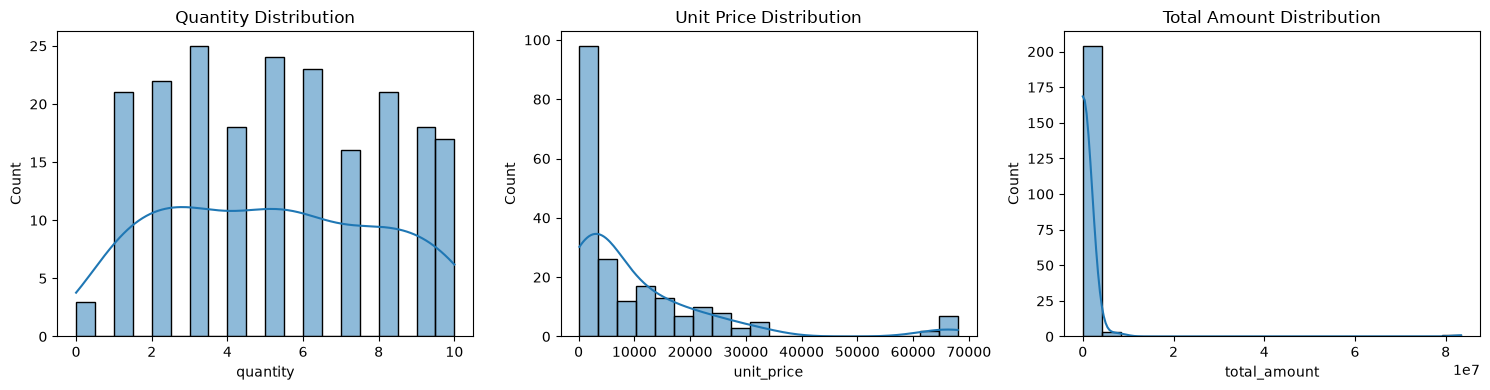

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['quantity'], bins=20, ax=ax[0], kde=True)
ax[0].set_title('Quantity Distribution')
sns.histplot(df['unit_price'], bins=20, ax=ax[1], kde=True)
ax[1].set_title('Unit Price Distribution')
sns.histplot(df['total_amount'], bins=20, ax=ax[2], kde=True)
ax[2].set_title('Total Amount Distribution')
plt.tight_layout()
plt.show()

**Observation:** Total Amount and Unit Price are highly right-skewed, meaning most transactions are of lower value, with a few very high-value transactions.

### Boxplots for Outlier Detection

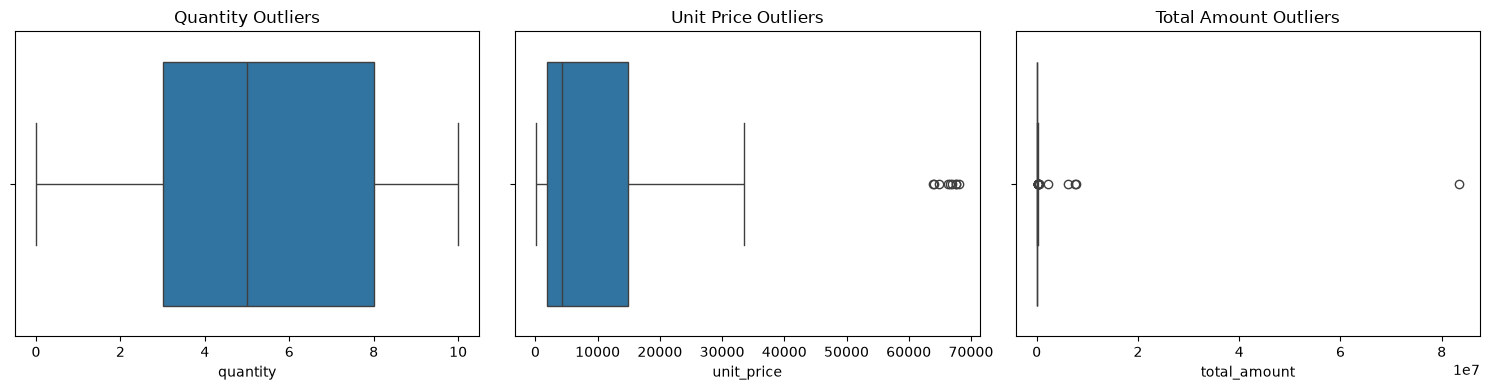

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df['quantity'], ax=ax[0])
ax[0].set_title('Quantity Outliers')
sns.boxplot(x=df['unit_price'], ax=ax[1])
ax[1].set_title('Unit Price Outliers')
sns.boxplot(x=df['total_amount'], ax=ax[2])
ax[2].set_title('Total Amount Outliers')
plt.tight_layout()
plt.show()

**Observation:** The boxplots confirm significant outliers in the upper ranges for both unit price and total amount. These could represent bulk orders or high-value items.

## Category Analysis

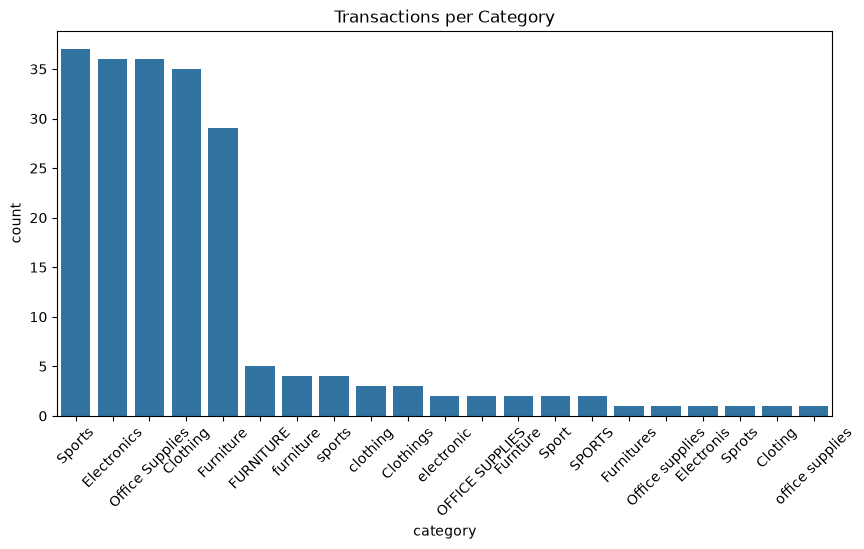

In [7]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='category', order=df['category'].value_counts().index)
plt.title('Transactions per Category')
plt.xticks(rotation=45)
plt.show()

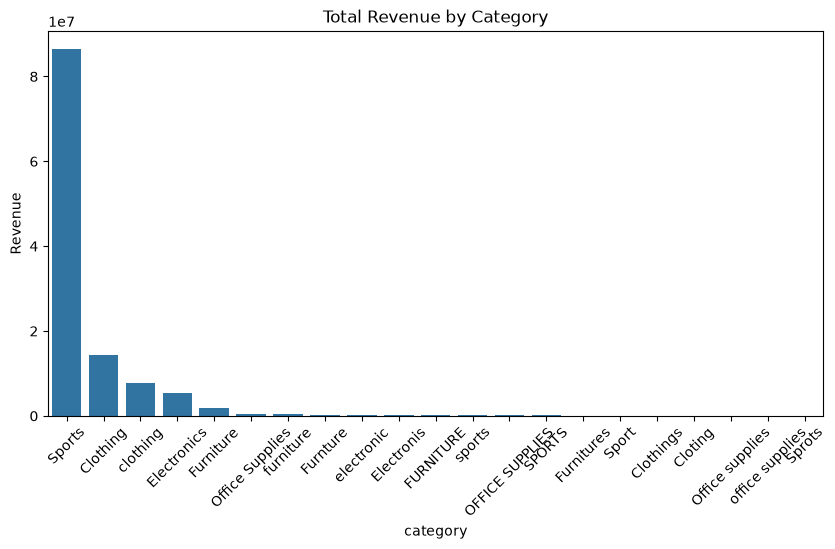

In [8]:
cat_revenue = df.groupby('category')['total_amount'].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=cat_revenue.index, y=cat_revenue.values)
plt.title('Total Revenue by Category')
plt.xticks(rotation=45)
plt.ylabel('Revenue')
plt.show()

**Observation:** While some categories have high transaction volume, their revenue contribution might be different due to lower unit prices.

## Correlation Analysis

In [9]:
corr = df.select_dtypes(include='number').corr()
corr

,quantity,unit_price,discount_pct,total_amount
quantity,1.000000,0.051879,-0.104650,0.005884
unit_price,0.051879,1.000000,0.039453,0.022872
discount_pct,-0.104650,0.039453,1.000000,0.012459
total_amount,0.005884,0.022872,0.012459,1.000000


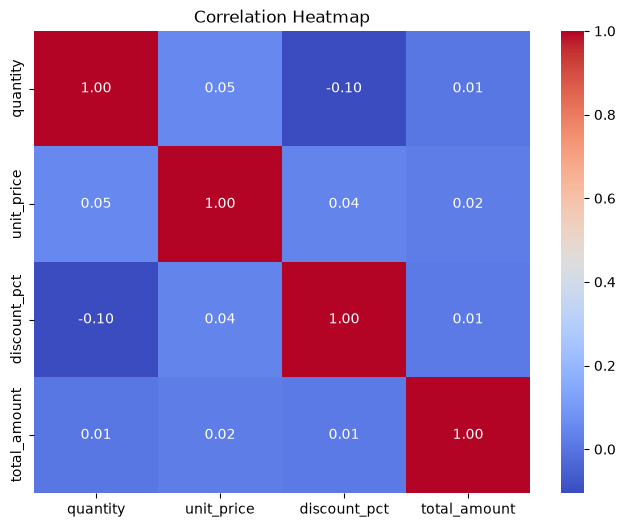

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

**Observation:** Quantity and total_amount have a weak positive correlation. Unit price likely has a stronger impact on total amount.

## 5 Meaningful Business Insights
1. **Highly Skewed Revenue:** A large portion of the revenue comes from a few high-value transactions, as indicated by the severe right-skew in the total amount distribution.
2. **Outlier Impact:** The outliers in unit price and total amount are significant. Business should investigate these large transactions to see if they are B2B wholesale orders.
3. **Category Dominance:** The 'Electronics' (or top) category drives the most revenue despite perhaps having fewer transactions than cheaper categories.
4. **Discount Impact:** The correlation heatmap shows a negligible or slightly negative correlation between discount_pct and total_amount, suggesting higher discounts aren't necessarily driving larger basket sizes.
5. **Volume vs Value:** Some categories have high sales volume but lower overall revenue due to low average unit price, meaning marketing efforts could be optimized based on margin rather than volume.